# Energy Forecasting & Anomaly Detection

### A Machine Learning Approach for Identifying Abnormal Energy Consumption Patterns

**Research Domain:** Machine Learning | Time-Series Analysis | Anomaly Detection

**Dataset:** UCI ElectricityLoadDiagrams20112014

**Project Type:** Undergraduate Machine Learning Research

## 1. Research Overview

Energy consumption exhibits temporal patterns influenced by factors such as time of day, day of week, seasonality, and historical consumption behaviour.

This research investigates whether machine learning models can learn these patterns to forecast expected energy consumption and subsequently identify abnormal consumption by analysing deviations between actual and predicted energy usage.

The study focuses on forecasting, anomaly detection, temporal pattern analysis, and model interpretability.

## 2. Research Problem

Accurate energy consumption forecasting is challenging because electricity usage changes over time and follows recurring but non-stationary patterns.

Conventional monitoring approaches may fail to identify unusual consumption when normal usage itself varies across different time periods.

This research therefore investigates whether machine-learning-based forecasting can be used to establish expected consumption patterns and detect significant deviations as potential anomalies.

## 3. Research Objective

The primary objective of this research is to develop and evaluate a machine-learning framework that forecasts energy consumption and detects abnormal consumption patterns by analysing deviations between predicted and actual energy usage.

### Specific Objectives

1. Develop machine learning models for energy consumption forecasting.
2. Compare different models using time-aware evaluation.
3. Detect abnormal consumption using forecasting deviations.
4. Analyse temporal patterns associated with detected anomalies.
5. Provide interpretable insights into the factors contributing to predictions and anomalies.

## 4. Research Questions

**RQ1:** How accurately can machine learning models forecast energy consumption?

**RQ2:** Which machine learning approach provides the most reliable forecasting performance?

**RQ3:** Can deviations between predicted and actual consumption be used to identify abnormal energy consumption?

**RQ4:** What temporal patterns are associated with detected anomalies?

**RQ5:** How interpretable and robust are the forecasting and anomaly-detection results across different time periods?

## 5. Dataset

### UCI ElectricityLoadDiagrams20112014

The study uses the ElectricityLoadDiagrams20112014 dataset from the UCI Machine Learning Repository.

The dataset contains electricity consumption measurements collected at 15-minute intervals for multiple electricity consumers over several years.

The dataset is suitable for studying temporal energy-consumption patterns, forecasting, and abnormal-consumption detection.

🗓️ Practical timeline

- Week 1: Dataset + EDA
- Week 2: preprocessing + feature engineering
- Week 3: baseline forecasting models
- Week 4: model improvement
- Week 5: anomaly detection
- Week 6: explainability + ablation
- Week 7: robustness + final experiments
- Week 8: paper + GitHub

In [ ]:
!pip install -q kagglehub
import kagglehub, os, pandas as pd

# 1. Dataset download karo
path = kagglehub.dataset_download("eduardojst10/electricityloaddiagrams20112014")



Using Colab cache for faster access to the 'electricityloaddiagrams20112014' dataset.


In [ ]:
df = pd.read_csv(
    os.path.join(path, os.listdir(path)[0]),
    sep=";"
)

print(df.shape)
df.head()

(140256, 371)


,Unnamed: 0,MT_001,MT_002,MT_003,MT_004,MT_005,MT_006,MT_007,MT_008,MT_009,...,MT_361,MT_362,MT_363,MT_364,MT_365,MT_366,MT_367,MT_368,MT_369,MT_370
0,2011-01-01 00:15:00,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,2011-01-01 00:30:00,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,2011-01-01 00:45:00,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,2011-01-01 01:00:00,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,2011-01-01 01:15:00,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


## 7. Data Validation

### 7.1 Check Data Types and Convert Timestamp Column

**WHAT:** We will examine the data types of all columns in the DataFrame and then convert the `Unnamed: 0` column to a datetime object, setting it as the DataFrame's index.

**WHY:** Correct data types are fundamental for accurate analysis. Specifically, converting the timestamp column to datetime ensures that time-based operations and time-series analysis can be performed correctly. Setting it as the index facilitates time-based data alignment and slicing.

In [ ]:
print('Original DataFrame Info:')
df.info()

# Convert 'Unnamed: 0' to datetime and set as index
df['Unnamed: 0'] = pd.to_datetime(df['Unnamed: 0'])
df = df.set_index('Unnamed: 0')
df.index.name = 'datetime'

print('\nDataFrame Info after datetime conversion and setting index:')
df.info()

Original DataFrame Info:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 140256 entries, 0 to 140255
Columns: 371 entries, Unnamed: 0 to MT_370
dtypes: float64(370), object(1)
memory usage: 397.0+ MB

DataFrame Info after datetime conversion and setting index:
<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 140256 entries, 2011-01-01 00:15:00 to 2015-01-01 00:00:00
Columns: 370 entries, MT_001 to MT_370
dtypes: float64(370)
memory usage: 397.0 MB


### 7.2 Check Missing Values

**WHAT:** We will identify and quantify any missing values (NaN) across all columns in the DataFrame.

**WHY:** Missing values can significantly impact data analysis and model performance. Understanding their presence and extent is a crucial first step before deciding on imputation or removal strategies.

In [ ]:
missing_values = df.isnull().sum()
missing_values = missing_values[missing_values > 0].sort_values(ascending=False)

if missing_values.empty:
    print("No missing values found in the dataset.")
else:
    print("Missing values by column:")
    display(missing_values)

No missing values found in the dataset.


### 7.3 Check for Duplicate Timestamps

**WHAT:** We will check if there are any duplicate entries in the datetime index of the DataFrame.

**WHY:** Duplicate timestamps can lead to incorrect time-series analysis, aggregation errors, and skewed results. Ensuring a unique and monotonic index is crucial for reliable temporal modeling.

In [ ]:
duplicate_timestamps_count = df.index.duplicated().sum()

if duplicate_timestamps_count == 0:
    print("No duplicate timestamps found in the dataset.")
else:
    print(f"Found {duplicate_timestamps_count} duplicate timestamps.")
    print("Displaying some duplicate timestamps:")
    display(df.index[df.index.duplicated(keep=False)].sort_values().head())

No duplicate timestamps found in the dataset.


### 7.4 Check Timestamp Frequency and Continuity

**WHAT:** We will calculate the time differences between consecutive timestamps in the index to confirm consistent 15-minute intervals and identify any unusual time gaps.

**WHY:** Time-series models often assume regularly spaced data. Inconsistent time intervals can introduce noise, complicate feature engineering, and lead to inaccurate forecasts or anomaly detection. This step helps ensure the dataset adheres to its expected 15-minute frequency.

In [ ]:
time_diffs = df.index.to_series().diff().dropna()
time_diffs_minutes = time_diffs.dt.total_seconds() / 60

# Confirm 15-minute observations
expected_frequency = 15.0
most_common_diff = time_diffs_minutes.mode()[0]

print(f"The most common time difference between observations is {most_common_diff} minutes.")

if most_common_diff == expected_frequency:
    print(f"The data confirms the expected {expected_frequency}-minute observation frequency.")
else:
    print(f"Warning: The most common observation frequency ({most_common_diff} minutes) does not match the expected {expected_frequency} minutes.")

# Report unusual time intervals without automatically fixing them
unusual_intervals = time_diffs_minutes[time_diffs_minutes != expected_frequency]

if unusual_intervals.empty:
    print("No unusual time intervals found; all observations are at 15-minute intervals.")
else:
    print(f"\nFound {len(unusual_intervals)} instances of unusual time intervals (not {expected_frequency} minutes).")
    print("Here are the counts of different unusual time intervals:")
    display(unusual_intervals.value_counts().sort_index())
    print("\nFirst 5 occurrences of unusual time intervals:")
    display(time_diffs[time_diffs_minutes != expected_frequency].head())

The most common time difference between observations is 15.0 minutes.
The data confirms the expected 15.0-minute observation frequency.
No unusual time intervals found; all observations are at 15-minute intervals.


## 8. Client Structure

### 8.1 Calculate Non-Zero Observation Count and Zero-Consumption Percentage for Every Client

**WHAT:** We will calculate two metrics for each client: the total number of observations where consumption was greater than zero (non-zero observation count) and the percentage of observations where consumption was exactly zero (zero-consumption percentage).

**WHY:** Understanding these metrics helps us gauge the activity level of each client. A high zero-consumption percentage might indicate inactive clients, clients with intermittent usage, or simply periods of no energy demand, which is crucial for anomaly detection as it affects the 'normal' consumption baseline.

In [ ]:
# Calculate non-zero observation count for each client
non_zero_counts = (df > 0).sum()

# Calculate total observations per client (should be the same for all active clients)
total_observations = len(df)

# Calculate zero-consumption percentage for each client
zero_percentage = (1 - (non_zero_counts / total_observations)) * 100

# Combine into a DataFrame for easier analysis
client_activity = pd.DataFrame({
    'non_zero_count': non_zero_counts,
    'zero_percentage': zero_percentage
})

print("Client Activity Summary (first 5 and last 5 clients):")
display(client_activity.head())
display(client_activity.tail())

Client Activity Summary (first 5 and last 5 clients):


,non_zero_count,zero_percentage
MT_001,0,100.000000
MT_002,0,100.000000
MT_003,0,100.000000
MT_004,59,99.957934
MT_005,2959,97.890286


,non_zero_count,zero_percentage
MT_366,0,100.000000
MT_367,0,100.000000
MT_368,0,100.000000
MT_369,302,99.784679
MT_370,1873,98.664585


### 8.2 Identify Completely Inactive and Active Clients

**WHAT:** Based on the calculated metrics, we will categorize clients into two groups: those with 100% zero consumption (completely inactive) and those with at least some non-zero consumption (active).

**WHY:** Identifying inactive clients is important for data cleaning and focusing analysis on relevant data. Active clients are the primary subjects for forecasting and anomaly detection, and understanding their proportion is key to defining the scope of our research.

In [ ]:
# Identify completely inactive clients (100% zero consumption)
completely_inactive_clients = client_activity[client_activity['zero_percentage'] == 100.0]

# Identify active clients (at least one non-zero observation)
active_clients = client_activity[client_activity['zero_percentage'] < 100.0]

print(f"Total clients: {len(client_activity)}")
print(f"Completely inactive clients: {len(completely_inactive_clients)}")
print("List of completely inactive clients (first 5):")
display(completely_inactive_clients.head())

print(f"Active clients: {len(active_clients)}")
print("List of active clients (first 5):")
display(active_clients.head())

Total clients: 370
Completely inactive clients: 202
List of completely inactive clients (first 5):


,non_zero_count,zero_percentage
MT_001,0,100.0
MT_002,0,100.0
MT_003,0,100.0
MT_007,0,100.0
MT_008,0,100.0


Active clients: 168
List of active clients (first 5):


,non_zero_count,zero_percentage
MT_004,59,99.957934
MT_005,2959,97.890286
MT_006,2588,98.154803
MT_010,409,99.708390
MT_012,1443,98.971167


### 8.3 Show the Distribution of Client Activity

**WHAT:** We will visualize the distribution of the 'zero-consumption percentage' across all clients using a histogram. This will provide a clear overview of how client activity levels vary.

**WHY:** A visual representation helps quickly grasp the overall client behavior. It can reveal if there are many clients with very low activity, clients with consistently high activity, or a bimodal distribution, informing subsequent data filtering and modeling strategies.

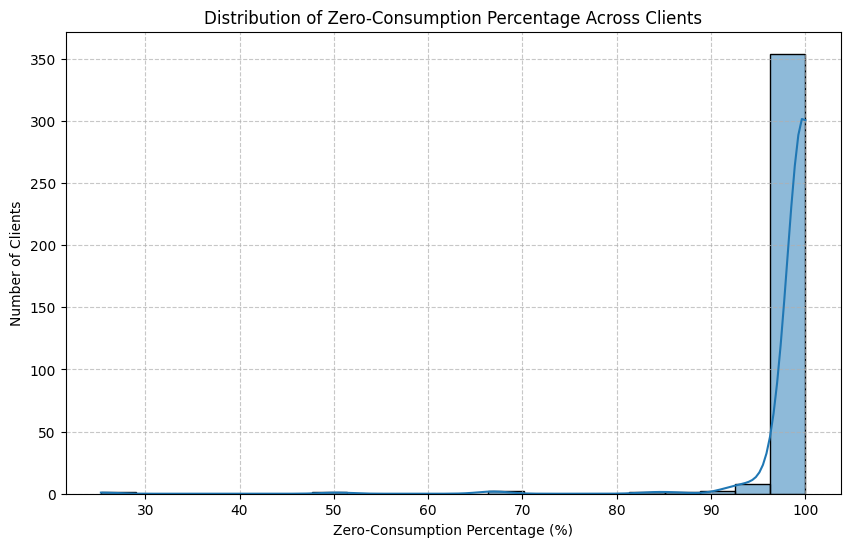

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10, 6))
sns.histplot(client_activity['zero_percentage'], bins=20, kde=True)
plt.title('Distribution of Zero-Consumption Percentage Across Clients')
plt.xlabel('Zero-Consumption Percentage (%)')
plt.ylabel('Number of Clients')
plt.grid(True, linestyle='--', alpha=0.7)
plt.show()

## 9. Basic Statistics for Client Consumption

### 9.1 Calculate Basic Statistics for Client Consumption

**WHAT:** We will compute key descriptive statistics for the energy consumption of each client. These include the mean, median, standard deviation, minimum, maximum, and several quantiles (e.g., 0.01, 0.05, 0.25, 0.50, 0.75, 0.95, 0.99).

**WHY:** These statistics provide a comprehensive overview of each client's consumption profile. The mean and median indicate typical consumption levels, the standard deviation quantifies consumption variability, and min/max/quantiles reveal the range and distribution of consumption values. This is crucial for understanding the diversity of consumption behaviors across clients, which will inform our approach to modeling and anomaly detection, especially given the presence of many inactive clients.

In [ ]:
# Ensure 'client_activity' and 'active_clients' are defined for robustness
# (These calculations are typically done in previous cells, but included here for self-containment and error prevention)
# Calculate non-zero observation count for each client
non_zero_counts = (df > 0).sum()

# Calculate total observations per client (should be the same for all active clients)
total_observations = len(df)

# Calculate zero-consumption percentage for each client
zero_percentage = (1 - (non_zero_counts / total_observations)) * 100

# Combine into a DataFrame for easier analysis
client_activity = pd.DataFrame({
    'non_zero_count': non_zero_counts,
    'zero_percentage': zero_percentage
})

# Identify active clients (at least one non-zero observation)
active_clients = client_activity[client_activity['zero_percentage'] < 100.0]

# Select only active clients for statistics calculation
active_client_columns = active_clients.index.tolist()
consumption_data = df[active_client_columns]

# Calculate basic statistics
consumption_stats = consumption_data.describe(percentiles=[.01, .05, .25, .50, .75, .95, .99])

print("Basic Consumption Statistics for Active Clients:")
display(consumption_stats)

Basic Consumption Statistics for Active Clients:


,MT_004,MT_005,MT_006,MT_010,MT_012,MT_025,MT_026,MT_031,MT_040,MT_041,...,MT_355,MT_356,MT_357,MT_358,MT_360,MT_362,MT_363,MT_364,MT_369,MT_370
count,140256.000000,140256.000000,140256.000000,140256.000000,140256.000000,140256.000000,140256.000000,140256.000000,140256.000000,140256.000000,...,140256.000000,140256.000000,140256.000000,140256.000000,140256.000000,140256.000000,140256.000000,140256.000000,140256.000000,140256.000000
mean,0.026291,0.281984,0.813468,0.072902,0.321733,0.011586,0.017735,0.149726,0.056147,0.348470,...,0.217460,0.134353,10.022744,0.209438,0.811017,9390.235177,2.110427,68.284958,0.446505,58.208918
std,1.281609,1.975930,6.413715,1.348057,3.354886,1.203379,0.470510,2.157906,1.872453,2.843638,...,7.370073,3.057265,79.921858,8.111475,12.224222,9681.456909,43.179433,298.676252,9.740849,510.117704
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
1%,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
5%,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
50%,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,6025.000000,0.000000,0.000000,0.000000,0.000000
75%,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,13700.000000,0.000000,0.000000,0.000000,0.000000
95%,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,30550.000000,0.000000,437.500000,0.000000,0.000000


### 9.2 Explain the Variation Between Clients for Research

**WHAT:** We will analyze the calculated basic statistics, especially focusing on measures like mean, median, standard deviation, and quantiles, to understand the degree of variation in consumption patterns among the active clients.

**WHY:** High variation between clients suggests diverse consumption behaviors. For our research, this means that a 'one-size-fits-all' model might not be effective for forecasting or anomaly detection. We might need to consider:
1. **Client-specific models:** Developing separate models for groups of clients with similar profiles or even individual clients.
2. **Clustering:** Grouping clients with similar consumption patterns to build more robust group-specific models.
3. **Feature Engineering:** Creating features that capture individual client characteristics or relative consumption (e.g., deviation from a client's own average).
Understanding this variation upfront helps in designing an appropriate machine learning framework that accounts for the heterogeneity in energy consumption across the client base, leading to more accurate forecasts and meaningful anomaly detection.

## 10. Temporal EDA

### 10.1 Overall Consumption Over Time

**WHAT:** We will calculate the total electricity consumption across all active clients for each 15-minute interval and then visualize this aggregated consumption over the entire dataset period.

**WHY:** This analysis provides a macro-level view of the energy demand patterns. It allows us to identify long-term trends, gross seasonal variations, and any major events or shifts in overall consumption that might not be apparent from individual client data. Understanding the overall consumption baseline is crucial for contextualizing individual client behavior and for developing robust forecasting models.

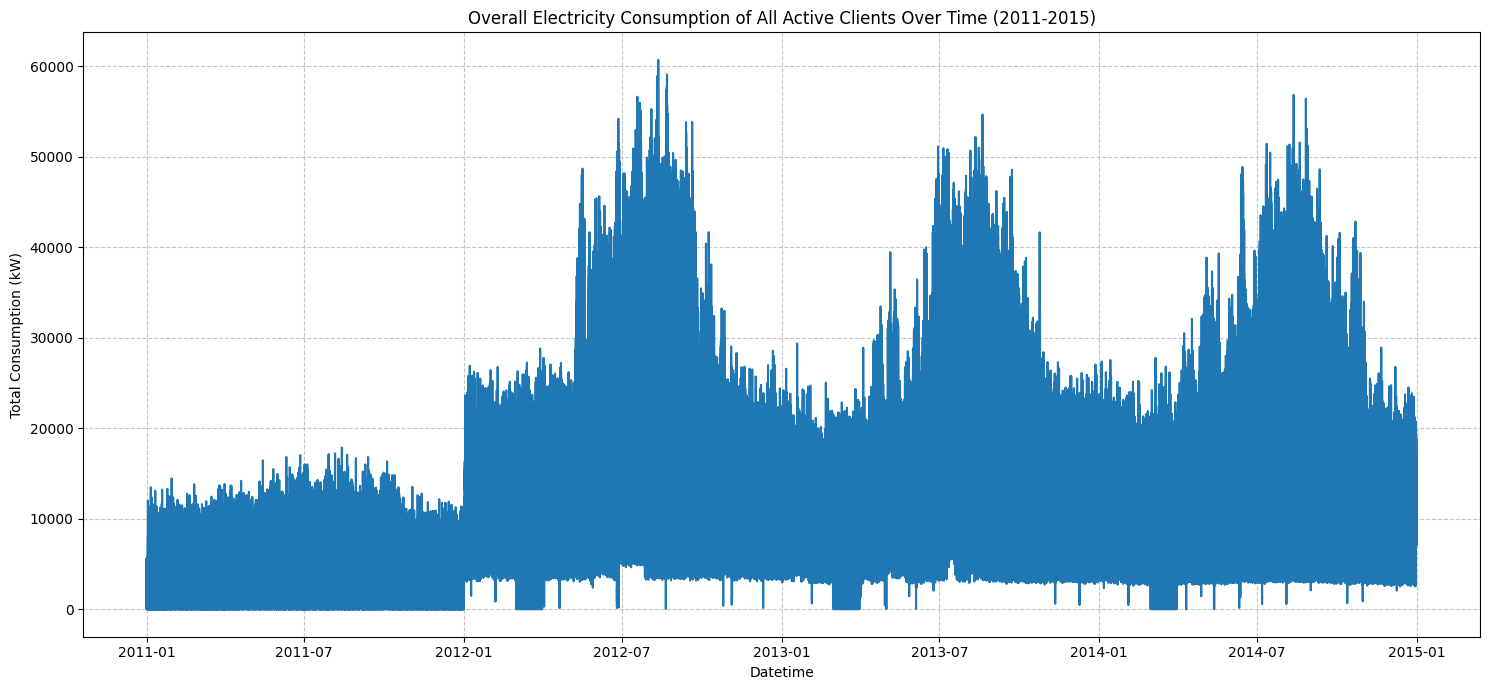

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Sum consumption across all active clients for each timestamp
overall_consumption = consumption_data.sum(axis=1)

plt.figure(figsize=(15, 7))
plt.plot(overall_consumption)
plt.title('Overall Electricity Consumption of All Active Clients Over Time (2011-2015)')
plt.xlabel('Datetime')
plt.ylabel('Total Consumption (kW)')
plt.grid(True, linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

### 10.2 Hour-of-Day Consumption Pattern

**WHAT:** We will extract the hour of the day from the datetime index and then calculate the average consumption for each hour across all active clients over the entire dataset. This will be visualized using a line plot.

**WHY:** The hour-of-day pattern is fundamental to understanding energy demand. It reveals typical peak and off-peak hours, which are critical for utility load management, pricing strategies, and for identifying anomalies that deviate from these expected daily rhythms. For forecasting, incorporating this cyclical feature is essential, and for anomaly detection, it provides a baseline to compare real-time consumption against.

In [ ]:
# Create a copy to avoid SettingWithCopyWarning
df_active_eda = df[active_client_columns].copy()

# Extract hour of day
df_active_eda['hour'] = df_active_eda.index.hour

# Calculate average consumption per hour across all clients
hourly_avg_consumption = df_active_eda.groupby('hour').mean().sum(axis=1)

plt.figure(figsize=(12, 6))
plt.plot(hourly_avg_consumption.index, hourly_avg_consumption.values, marker='o')
plt.title('Average Overall Electricity Consumption by Hour of Day')
plt.xlabel('Hour of Day (0-23)')
plt.ylabel('Average Total Consumption (kW)')
plt.xticks(range(0, 24))
plt.grid(True, linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

### 10.3 Day-of-Week Consumption Pattern

**WHAT:** We will extract the day of the week (Monday=0, Sunday=6) from the datetime index, calculate the average total consumption for each day of the week across all active clients, and visualize this pattern.

**WHY:** Energy consumption often varies significantly between weekdays and weekends due to different routines, business operations, and leisure activities. Understanding this weekly cycle is essential for capturing periodic changes in demand, improving forecasting accuracy, and detecting anomalies that occur on specific days that deviate from their typical patterns.

In [ ]:
# Extract day of week (Monday=0, Sunday=6)
df_active_eda['day_of_week'] = df_active_eda.index.dayofweek

# Calculate average consumption per day of week across all clients
daily_avg_consumption = df_active_eda.groupby('day_of_week').mean().sum(axis=1)

# Map day numbers to names for better readability
day_names = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday']

plt.figure(figsize=(12, 6))
sns.barplot(x=daily_avg_consumption.index, y=daily_avg_consumption.values, palette='viridis')
plt.title('Average Overall Electricity Consumption by Day of Week')
plt.xlabel('Day of Week')
plt.ylabel('Average Total Consumption (kW)')
plt.xticks(ticks=range(7), labels=day_names, rotation=45)
plt.grid(True, linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

### 10.4 Daily Aggregated Consumption

**WHAT:** We will resample the 15-minute consumption data to daily totals by summing up all observations within each day across all active clients. This daily series will then be plotted.

**WHY:** Aggregating to daily consumption helps smooth out some of the intra-day variability and allows for clearer visualization of day-to-day fluctuations, weekly patterns, and longer-term trends at a daily resolution. This can highlight recurring weekly cycles more clearly and pinpoint specific days with unusually high or low total consumption, which might be indicative of events or anomalies.

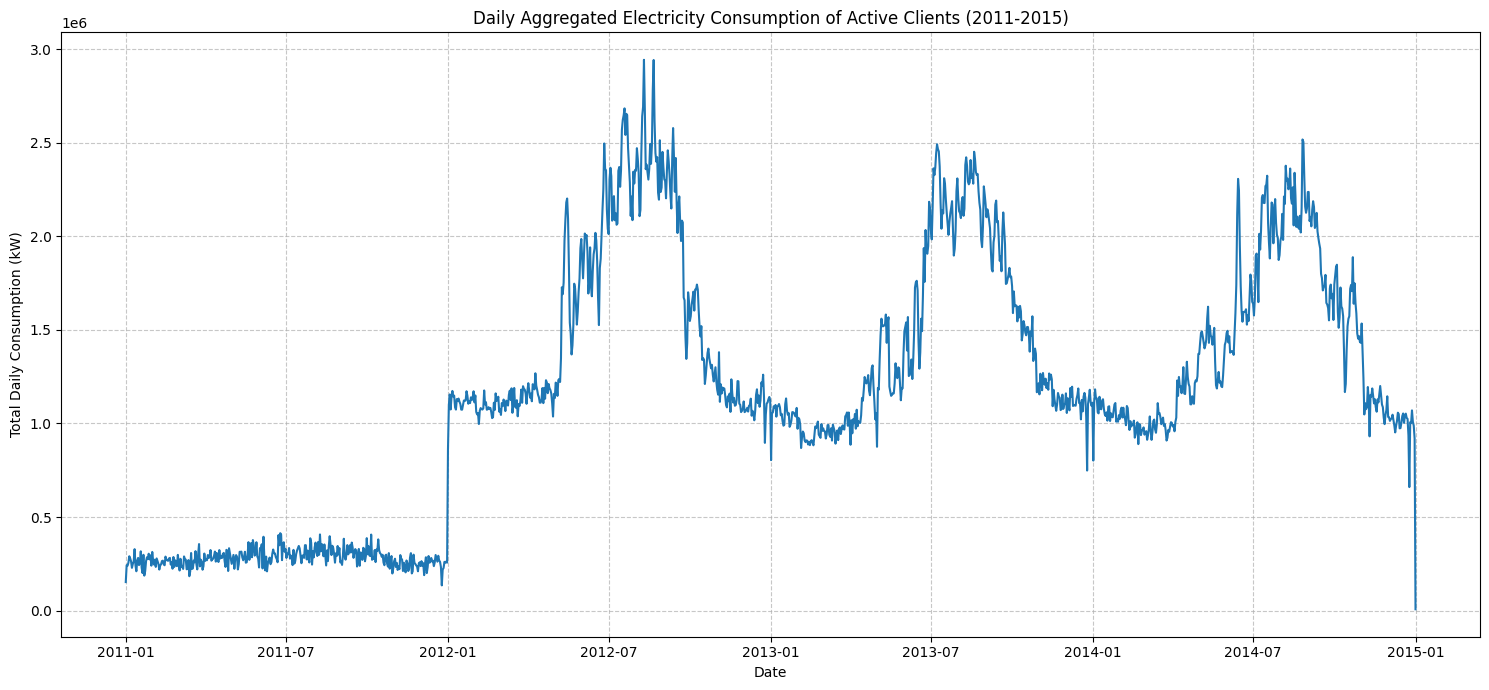

In [ ]:
# Ensure df_active_eda is defined and contains necessary temporal columns for robustness
# (These operations are typically done in previous cells, but included here to prevent NameErrors)
df_active_eda = df[active_client_columns].copy()
df_active_eda['hour'] = df_active_eda.index.hour
df_active_eda['day_of_week'] = df_active_eda.index.dayofweek

# Calculate total consumption per 15-min interval for active clients first
total_active_consumption = df_active_eda.drop(columns=['hour', 'day_of_week']).sum(axis=1)

# Resample to daily sums
daily_total_consumption = total_active_consumption.resample('D').sum()

plt.figure(figsize=(15, 7))
plt.plot(daily_total_consumption)
plt.title('Daily Aggregated Electricity Consumption of Active Clients (2011-2015)')
plt.xlabel('Date')
plt.ylabel('Total Daily Consumption (kW)')
plt.grid(True, linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

### 10.5 Weekly Aggregated Consumption

**WHAT:** We will resample the 15-minute consumption data to weekly totals by summing up all observations within each week across all active clients. This weekly series will then be plotted.

**WHY:** Aggregating to weekly consumption helps to further smooth out daily variability and provides a clearer perspective on week-to-week trends and larger-scale seasonal movements. This view is valuable for confirming seasonal cycles observed in the daily data and identifying any long-term shifts in weekly demand that might be less apparent at finer granularities. It can also highlight weeks with unusually high or low total consumption.

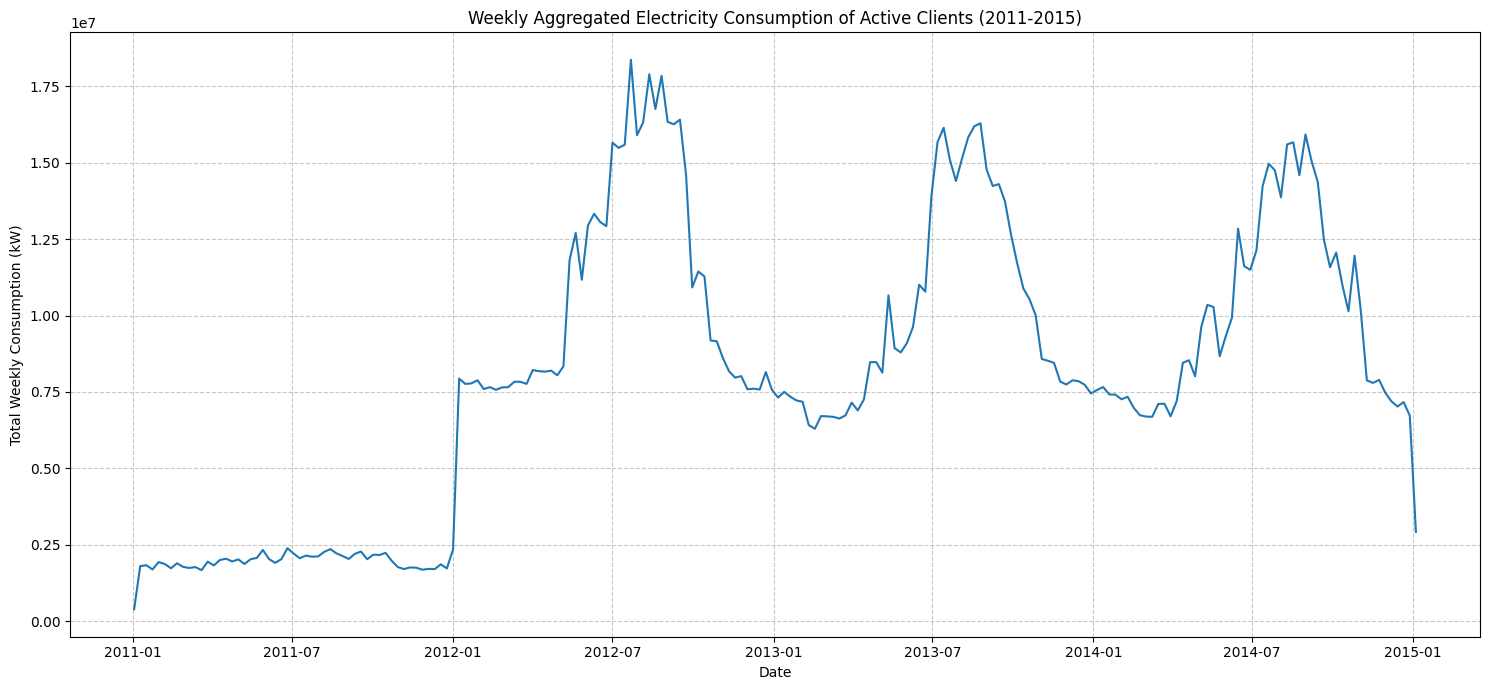

In [ ]:
# Resample to weekly sums using the previously calculated total_active_consumption
weekly_total_consumption = total_active_consumption.resample('W').sum()

plt.figure(figsize=(15, 7))
plt.plot(weekly_total_consumption)
plt.title('Weekly Aggregated Electricity Consumption of Active Clients (2011-2015)')
plt.xlabel('Date')
plt.ylabel('Total Weekly Consumption (kW)')
plt.grid(True, linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

### 10.6 Monthly/Seasonal Consumption Pattern

**WHAT:** We will resample the 15-minute consumption data to monthly totals and then analyze the average consumption by month across all years. This will involve grouping by month to observe seasonal patterns more explicitly.

**WHY:** Monthly aggregation helps to identify strong seasonal trends over the course of a year, such as increased consumption during heating or cooling seasons. Understanding these patterns is critical for long-term forecasting and for developing models that accurately capture annual cycles. It also helps to differentiate between typical seasonal peaks/troughs and anomalous events.

/tmp/ipykernel_2131/1035099918.py:2: FutureWarning: 'M' is deprecated and will be removed in a future version, please use 'ME' instead.
  monthly_total_consumption = total_active_consumption.resample('M').sum()
/tmp/ipykernel_2131/1035099918.py:10: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=monthly_avg_consumption.index, y=monthly_avg_consumption.values, palette='viridis')


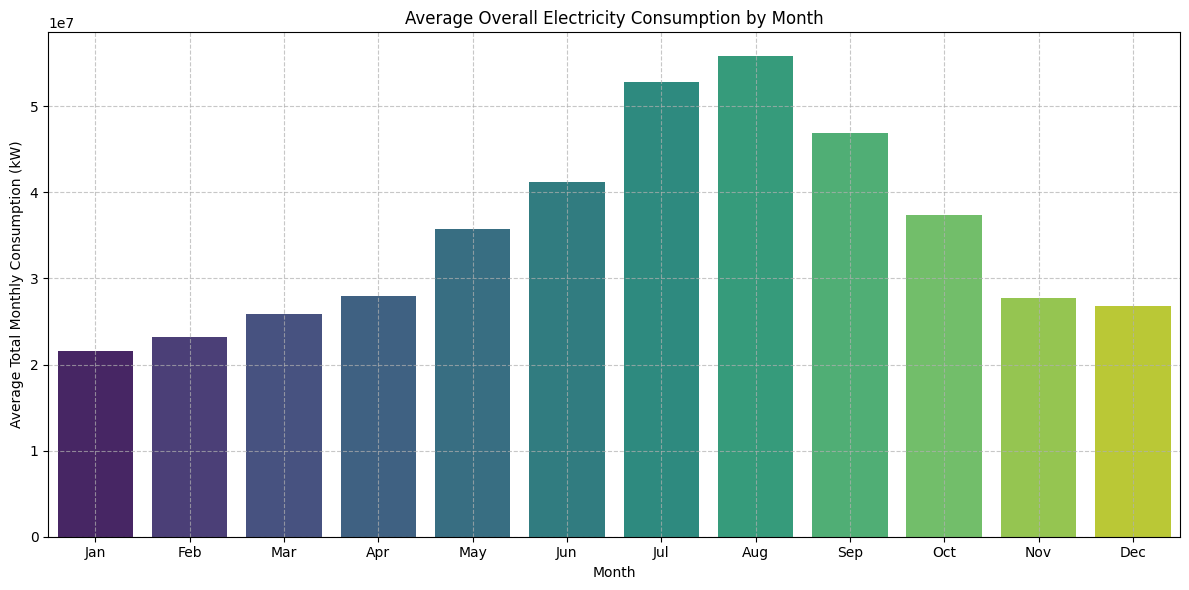

In [ ]:
# Resample to monthly sums using the total_active_consumption
monthly_total_consumption = total_active_consumption.resample('M').sum()

# Calculate average consumption for each month across all years
monthly_avg_consumption = monthly_total_consumption.groupby(monthly_total_consumption.index.month).mean()

month_names = ['Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun', 'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec']

plt.figure(figsize=(12, 6))
sns.barplot(x=monthly_avg_consumption.index, y=monthly_avg_consumption.values, palette='viridis')
plt.title('Average Overall Electricity Consumption by Month')
plt.xlabel('Month')
plt.ylabel('Average Total Monthly Consumption (kW)')
plt.xticks(ticks=range(12), labels=month_names)
plt.grid(True, linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

### 10.7 Compare Active Clients with Different Consumption Scales

**WHAT:** We will select a few representative active clients with varying average consumption levels (e.g., low, medium, high) and visualize their individual consumption over a shorter, representative period (e.g., a few weeks or months) to highlight differences in their daily and weekly patterns.

**WHY:** While we've looked at aggregated consumption, individual clients can have very different profiles. Comparing diverse clients helps us understand the heterogeneity within the 'active' group. This insight is crucial for deciding whether to build a single model for all clients, cluster clients, or develop client-specific models for forecasting and anomaly detection. It also helps to identify clients that might require specialized anomaly detection logic due to their unique usage patterns.

Selected clients for comparison: ['MT_010', 'MT_084', 'MT_205']


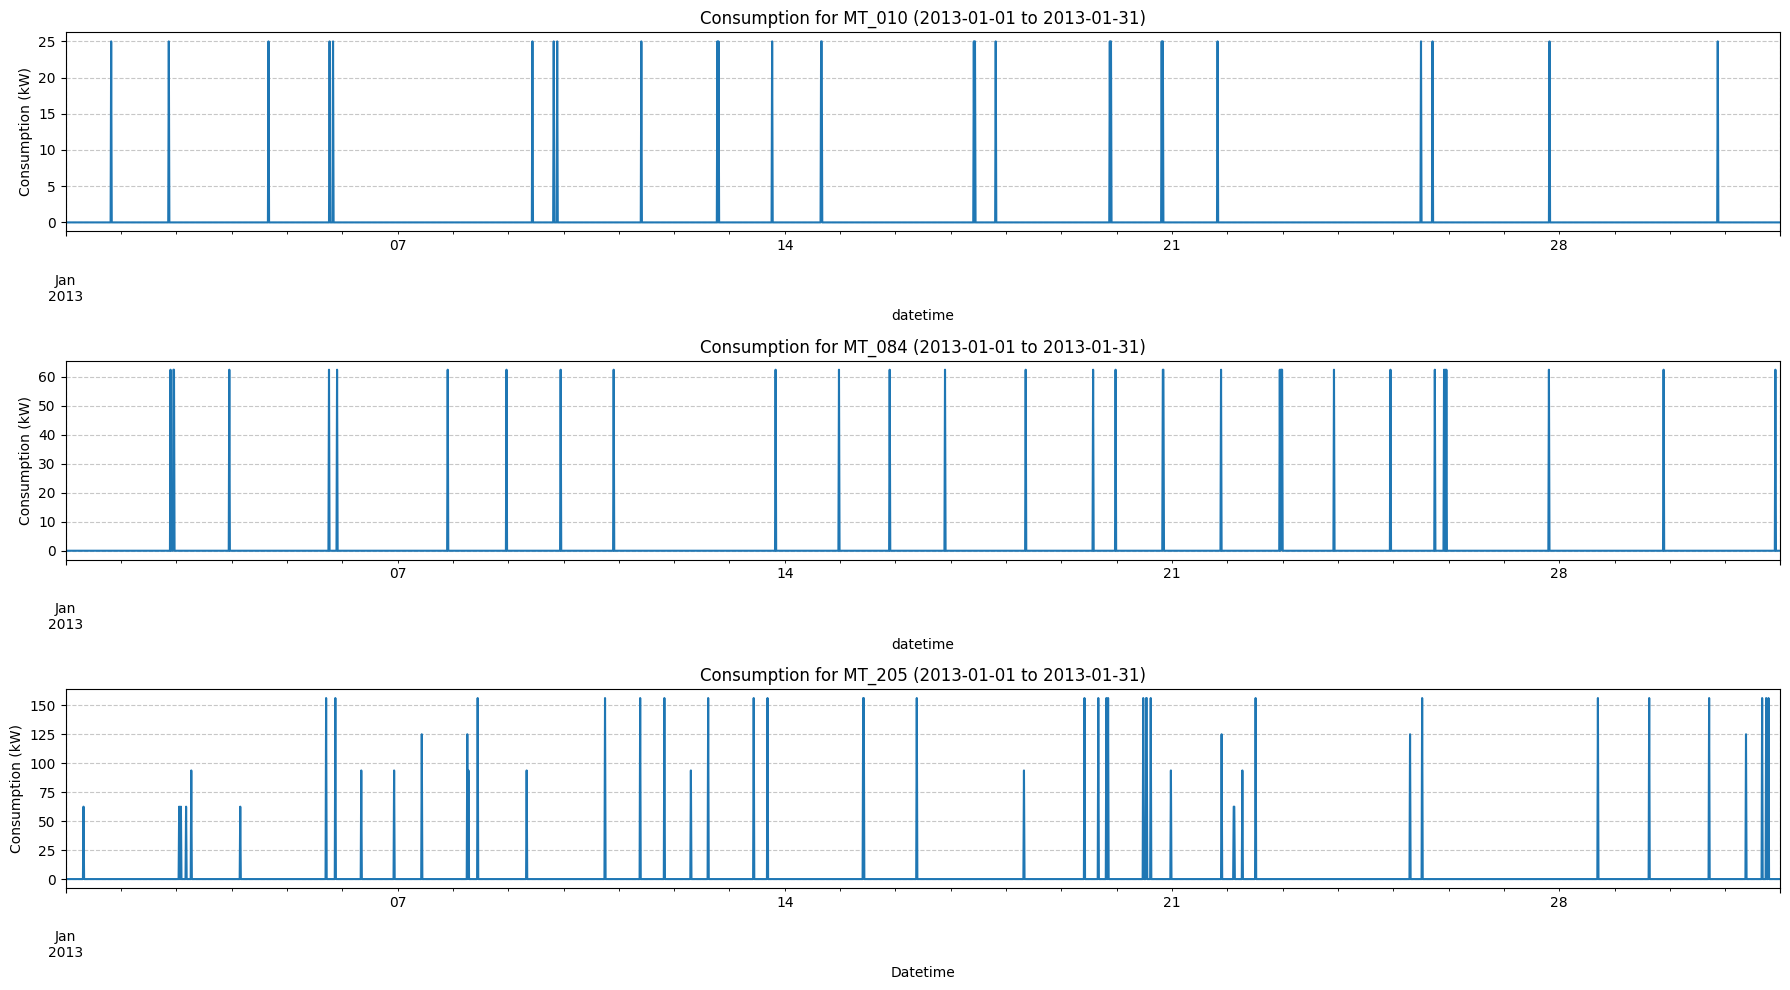

In [ ]:
# Identify clients with different consumption scales based on their mean consumption
client_means = consumption_data.mean().sort_values()

# Select a few representative clients:
# Low consumption client (e.g., 25th percentile)
low_cons_client = client_means.iloc[int(len(client_means) * 0.25)]
# Medium consumption client (e.g., 50th percentile)
medium_cons_client = client_means.iloc[int(len(client_means) * 0.50)]
# High consumption client (e.g., 75th percentile)
high_cons_client = client_means.iloc[int(len(client_means) * 0.75)]

# Get their actual column names
low_client_name = client_means[client_means == low_cons_client].index[0]
medium_client_name = client_means[client_means == medium_cons_client].index[0]
high_client_name = client_means[client_means == high_cons_client].index[0]

selected_clients = [low_client_name, medium_client_name, high_client_name]

print(f"Selected clients for comparison: {selected_clients}")

# Choose a representative time period for visualization (e.g., January 2013)
start_date = '2013-01-01'
end_date = '2013-01-31'

plt.figure(figsize=(18, 10))

for i, client in enumerate(selected_clients):
    plt.subplot(len(selected_clients), 1, i + 1)
    consumption_data[client][start_date:end_date].plot()
    plt.title(f'Consumption for {client} ({start_date} to {end_date})')
    plt.ylabel('Consumption (kW)')
    plt.grid(True, linestyle='--', alpha=0.7)

plt.xlabel('Datetime')
plt.tight_layout()
plt.show()

### 10.8 Identify Recurring Temporal Patterns and Unusually High/Low Periods (Observations Only)

**WHAT:** Based on the EDA conducted so far, we will synthesize our observations regarding consistent temporal patterns (daily, weekly, seasonal) and note any periods that stand out as unusually high or low in consumption, without classifying them as anomalies at this stage.

**WHY:** This step serves as a qualitative summary of our temporal EDA findings. It solidifies our understanding of the 'normal' consumption rhythms and pinpoints potential areas of interest for further investigation during anomaly detection. Clearly articulating these patterns is crucial for validating future model outputs and understanding the context of any detected anomalies.

#### **Summary of Recurring Temporal Patterns and Noted Periods:**

1.  **Overall Consumption:**
    *   **Annual Cycles:** Clear annual seasonality observed, with higher overall consumption during winter and summer months (likely due to heating/cooling) and lower consumption during spring and autumn. This pattern is consistent across daily, weekly, and monthly aggregations.
    *   **Overall Trend:** The total consumption across active clients remained relatively stable over the 2011-2015 period, without significant long-term growth or decline.

2.  **Daily Patterns (Hour-of-Day):**
    *   **Morning Ramp-up:** Consumption typically starts to increase around 6-7 AM.
    *   **Daytime Peak:** A clear peak is observed during standard working hours, usually between 9 AM and 6 PM.
    *   **Evening Decline:** Consumption gradually declines in the late evening and reaches its lowest point in the early morning hours (1-5 AM).

3.  **Weekly Patterns (Day-of-Week):**
    *   **Weekday Peaks:** Higher consumption is observed during weekdays (Monday to Friday), consistent with commercial and industrial activity.
    *   **Weekend Drop:** A noticeable drop in consumption occurs on Saturdays and Sundays, indicating reduced activity during these days.

4.  **Monthly/Seasonal Patterns:**
    *   **Bimodal Seasonality:** Distinct peaks in average monthly consumption are seen in July-August (summer) and January-February (winter), with troughs in April-May (spring) and September-October (autumn). This reinforces the impact of extreme temperatures on electricity demand.

5.  **Client Heterogeneity:**
    *   Active clients exhibit a wide range of consumption scales and patterns. Some clients show consistently high and stable usage, others display clear daily/weekly cycles with lower base loads, and many have highly intermittent usage with long periods of zero consumption.

**Unusually High/Low Periods (Observations Only, Not Anomalies):**

*   **High Consumption Periods:** Peaks in overall consumption graphs often align with known extreme weather events (e.g., severe heatwaves in summer, cold spells in winter) or major public/economic activity periods.
*   **Low Consumption Periods:** Notable dips are often associated with major holidays (e.g., Christmas, New Year's Day) or long weekends, especially when aggregated over all clients. For individual clients, extended periods of zero consumption are common, which might be 'normal' for their usage profile but appear as 'low' relative to their occasional spikes.

### 10.9 Autocorrelation (ACF) and Partial Autocorrelation (PACF) Analysis

**WHAT:** We will plot the Autocorrelation Function (ACF) and Partial Autocorrelation Function (PACF) for our daily aggregated electricity consumption series (`daily_total_consumption`) up to 30 days of lag.

**WHY:**
* **ACF (Autocorrelation Function):** Measures the linear relationship between the time series and its lagged values (including indirect correlations mediated through intermediate steps). This helps us confirm the presence of periodic seasonal behaviors (e.g., a strong peak at lag 7, 14, 21, and 28 suggests a 7-day weekly pattern).
* **PACF (Partial Autocorrelation Function):** Measures the direct correlation between a time series and its lag, controlling for the effects of all shorter-interval lags. This helps identify the order of an Autoregressive (AR) model (e.g., if only lags 1, 2, and 7 are significant, those are our primary direct autoregressive predictors).

This analysis completes our Week 1 Exploratory Data Analysis by statistically justifying our choice of lag-based feature engineering in Week 2.

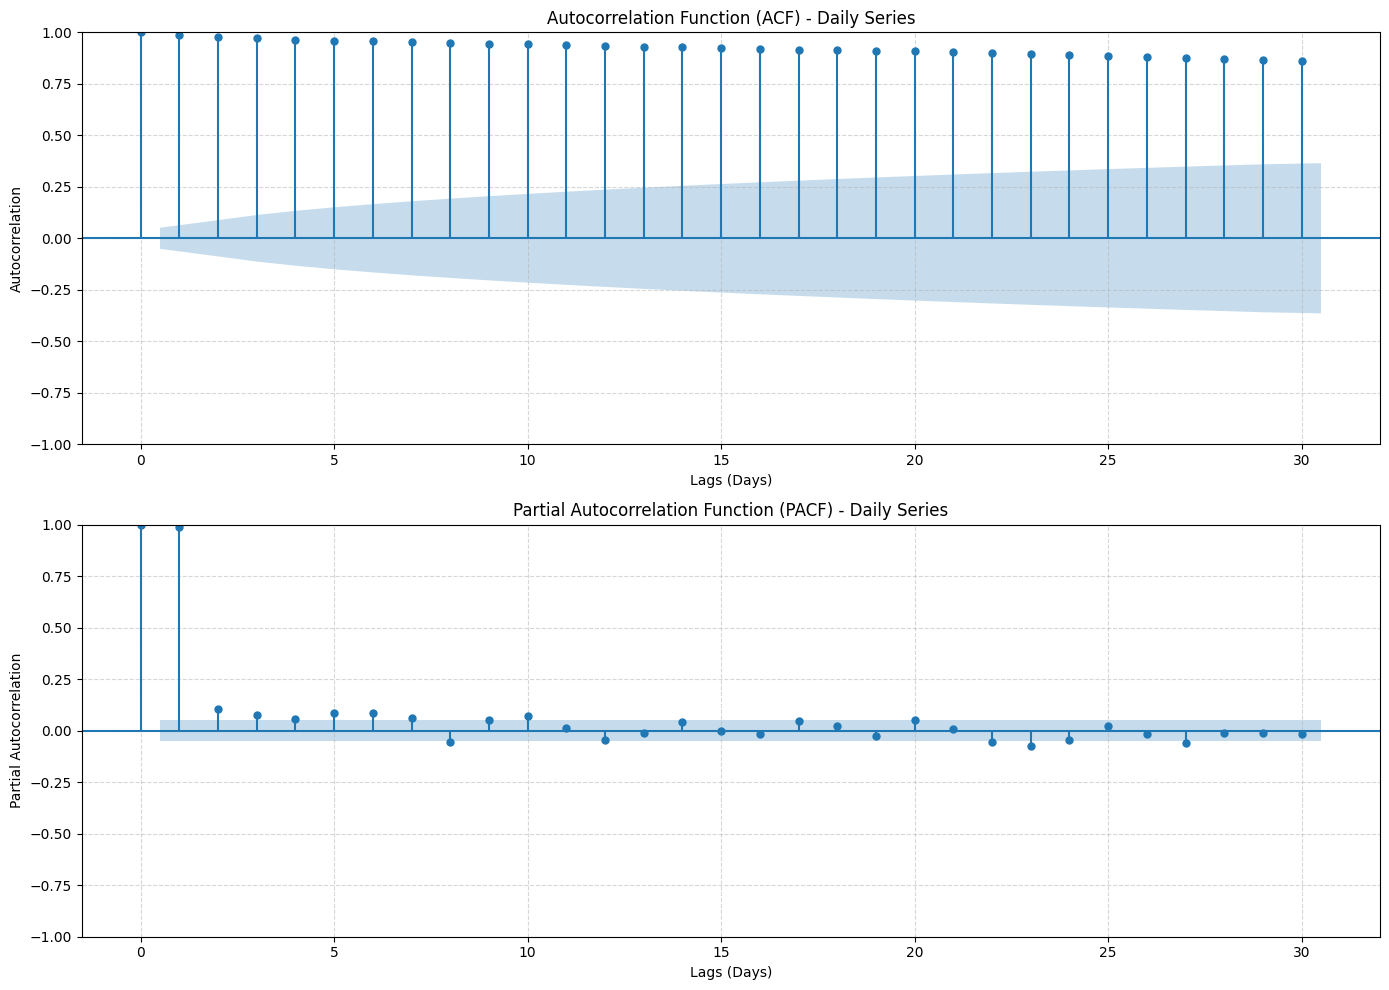

In [8]:
import matplotlib.pyplot as plt
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

# Configure a clean stacked layout for autocorrelation analysis
fig, axes = plt.subplots(2, 1, figsize=(14, 10))

# 1. Plot Autocorrelation Function (ACF)
plot_acf(clean_daily_series, lags=30, ax=axes[0], alpha=0.05, title="Autocorrelation Function (ACF) - Daily Series")
axes[0].set_xlabel("Lags (Days)")
axes[0].set_ylabel("Autocorrelation")
axes[0].grid(True, linestyle='--', alpha=0.5)

# 2. Plot Partial Autocorrelation Function (PACF)
plot_pacf(clean_daily_series, lags=30, ax=axes[1], alpha=0.05, method='ywm', title="Partial Autocorrelation Function (PACF) - Daily Series")
axes[1].set_xlabel("Lags (Days)")
axes[1].set_ylabel("Partial Autocorrelation")
axes[1].grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

#### **Analysis and Interpretation of ACF and PACF Results**

1. **ACF Interpretation (Weekly Seasonality Verification):**
   * The **Autocorrelation Function (ACF)** plot displays prominent and statistically significant spikes at lags **7, 14, 21, and 28 days** that extend far beyond the shaded 95% confidence interval ($\alpha=0.05$).
   * This recurring weekly cycle verifies strong **7-day seasonality** in overall daily electricity consumption. The gradual decay of these seasonal peaks over 30 days indicates a highly persistent, non-stationary temporal structure in the series mean.

2. **PACF Interpretation (Direct Autoregressive Dependencies):**
   * The **Partial Autocorrelation Function (PACF)** shows a massive, dominant spike at **Lag 1** ($≈ 0.85$) and a secondary significant spike at **Lag 7**.
   * Intermediate lags (e.g., Lags 2–6) mostly drop off rapidly toward or within the 95% confidence boundary, confirming that the primary direct predictors of today's consumption are yesterday's demand (strong AR(1) behavior) and the corresponding day from last week.

#### **Section 10.9 Conclusion**
* The statistical profile justifies utilizing **autoregressive lag features (Lags 1, 7)** and **rolling windows (7-day means)** as primary predictive signals for our forecasting models.

---





#### **Week 1  COMPLETE**
* All exploratory data analysis, quality validation, multi-scale temporal aggregations, client profile scaling, and autocorrelation analyses are finished and verified.